# Group theory 4: Groups as objects

*Learning path: group theory, part 4 of 4.* [Index](README.md) · Previous: [Permutations and Lagrange's theorem](03-permutations-and-lagrange.ipynb)

**The question.** In lesson 3 a group was a list of permutations. Mathematicians think of a group as one object that
you can take apart: cut into cosets, divide by a normal subgroup, compare with another group. Can a computer do that
too, and what does it tell us about why some equations have no formula?

**Who this is for:** anyone who has done lessons 1 to 3. **You need:** permutations, cosets and Lagrange's theorem.

**You will learn**

* to build groups by name (`sym`, `alt`, `cyclic`, `dihedral`, `units`, `group("Q8")`) and from rules (presentations),
* subgroups, normal subgroups and **quotient groups** $G/N$,
* **conjugacy classes** and the class equation,
* **Sylow subgroups**, the subgroups whose size is forced by $|G|$,
* homomorphisms, kernels and **isomorphism**: when two groups are "the same",
* the **derived series**, solvable groups, and why $A_5$ blocks a formula for the quintic.

## 1. A group is a value

`sym(4)` is the symmetric group $S_4$, all 24 permutations of 4 things. It prints as the call that builds it, so you
can store it, pass it on and get it back. `gens` shows the generators Galileo keeps: a swap and a 4-cycle.

In [1]:
G = sym(4)
order(G)
gens(G)

sym(4)

> `sym(4)`: a group of order 24.

24

> `order`: order(G) is the number of elements of G.

[2, 1, 3, 4;
 2, 3, 4, 1]

The symmetries of a square form the **dihedral group** $D_4$ of order 8: four rotations and four reflections.
A **Cayley graph** draws a group: one dot per element, and an arrow of each color for multiplying by each generator.
Blue arrows (the rotation $(1\ 2\ 3\ 4)$) go round in squares; red arrows (a reflection) jump between the two squares.

dihedral(4)

> `dihedral(4)`: a group of order 8.

8

> `order`: order(G) is the number of elements of G.

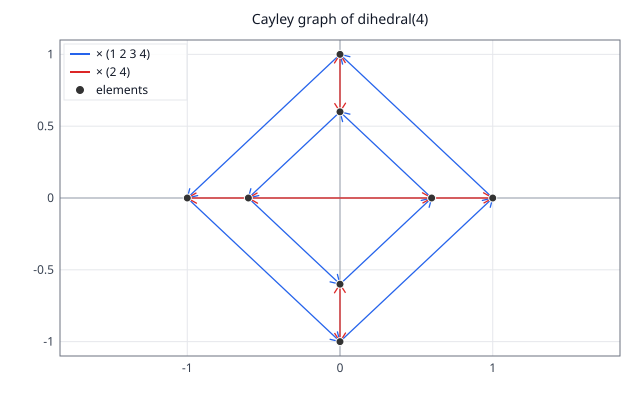

In [2]:
D = dihedral(4)
order(D)
cayleygraph(D)

**Try this:** draw `cayleygraph(cyclic(6))` and `cayleygraph(alt(4))`. Which one is a single cycle, and why?

## 2. Normal subgroups and quotients

The four permutations $e$, $(1\ 2)(3\ 4)$, $(1\ 3)(2\ 4)$, $(1\ 4)(2\ 3)$ form a subgroup $V$ of $S_4$ (the Klein
four-group). Its cosets cut the 24 elements into 6 pieces of 4, one representative per row:

In [3]:
V = subgroup(G, [2, 1, 4, 3], [3, 4, 1, 2])
cosets(G, V)

group([2, 1, 4, 3], [3, 4, 1, 2])

> A subgroup of order 4; by Lagrange's theorem it divides 24 = |G| (index 6).

[1, 2, 3, 4;
 1, 2, 4, 3;
 1, 3, 2, 4;
 1, 3, 4, 2;
 1, 4, 2, 3;
 1, 4, 3, 2]

> 6 left cosets gH of 4 elements each: 24 = 6 · 4 (Lagrange). One representative per row.

$V$ is **normal**: $gVg^{-1} = V$ for every $g$. Then the cosets themselves multiply ($aV \cdot bV = abV$) and form a
group, the **quotient** $G/V$, of order $24/4 = 6$. A swap generates a subgroup $H$ that is not normal, and for it
`quotient` refuses, because the product of cosets would depend on which representatives you picked.

In [4]:
isnormal(G, V)
H = subgroup(G, [2, 1, 3, 4])
isnormal(G, H)
Q = quotient(G, V)
order(Q)
isomorphic(Q, sym(3))

true

group([2, 1, 3, 4])

> A subgroup of order 2; by Lagrange's theorem it divides 24 = |G| (index 12).

false

quotient(sym(4), group([2, 1, 4, 3], [3, 4, 1, 2]))

> G/N has order 24 / 4 = 6; its elements are the cosets of N, acting here as permutations of the cosets.

6

> `order`: order(G) is the number of elements of G.

true

> An isomorphism, sending generators (in cycle notation) to: (1 2)(3 5)(4 6) ↦ (1 2), (1 6)(2 5)(3 4) ↦ (2 3).

So $S_4 / V \cong S_3$. This is a real fact about geometry: $S_4$ is the rotation group of a cube, $V$ the half-turns
about the three axes through face centers, and $S_3$ is what is left: how the three axes are permuted.

**Check yourself:** what is the order of `quotient(G, alt(4))`? (Answer in the exercises.)

## 3. Conjugacy classes

Two elements are **conjugate** when $b = gag^{-1}$ for some $g$: the same motion seen from a different viewpoint. In
$S_n$ conjugate means "same cycle shape". `classes` gives one representative per class; the note adds the class
equation, the group split into classes:

In [5]:
classes(G)

[1, 2, 3, 4;
 1, 2, 4, 3;
 1, 3, 4, 2;
 2, 1, 4, 3;
 2, 3, 4, 1]

> 5 conjugacy classes (one representative per row, in cycle notation (), (3 4), (2 3 4), (1 2)(3 4), (1 2 3 4)). Class equation: 24 = 1 + 6 + 8 + 3 + 6.

$24 = 1 + 6 + 8 + 3 + 6$: the identity, the 6 swaps, the 8 three-cycles, the 3 double swaps and the 6 four-cycles.
Each class size divides $|G|$, and the classes of size 1 form the **center**, the elements that commute with
everything. $S_4$ has a trivial center; $D_4$ has a center of order 2 (the half-turn):

In [6]:
order(center(G))
order(center(D))

1

> `order`: order(G) is the number of elements of G.

2

> `order`: order(G) is the number of elements of G.

## 4. Isomorphism: when are two groups the same?

The quaternion group $Q_8 = \{\pm 1, \pm i, \pm j, \pm k\}$ and $D_4$ both have 8 elements and neither is abelian. Are
they the same group in disguise? Count element orders: `orders` gives [order, how many].

In [7]:
orders(group("Q8"))
orders(D)
isomorphic(group("Q8"), D)

[1, 1;
 2, 1;
 4, 6]
[1, 1;
 2, 5;
 4, 2]
false

> No isomorphism: the orders, element orders or class sizes differ, or no assignment of generators works.

$Q_8$ has six elements of order 4 and one of order 2; $D_4$ has two of order 4 and five of order 2. An isomorphism
keeps orders, so they are different groups. When `isomorphic` says yes, its note gives the map.

A **homomorphism** only has to respect multiplication. The sign of a permutation is one: $S_4 \to \{\pm 1\} \cong C_2$,
both generators (a swap and a 4-cycle) are odd and go to the swap $[2, 1]$. Its **kernel**, what goes to the identity,
is $A_4$, and the first isomorphism theorem says $|G| = |\ker| \cdot |\text{image}|$:

In [8]:
K = kernel(G, cyclic(2), [2, 1], [2, 1])
order(K)
isomorphic(K, alt(4))

group([1, 3, 4, 2], [1, 4, 2, 3], [2, 1, 4, 3], [2, 3, 1, 4], [2, 4, 3, 1], [3, 1, 2, 4], [3, 2, 4, 1], [3, 4, 1, 2], [4, 1, 3, 2], [4, 2, 1, 3], [4, 3, 2, 1])

> The kernel (what goes to the identity) has order 12, the image order 2: |G| = 24 = 12 · 2 (first isomorphism theorem, G/ker ≅ image).

12

> `order`: order(G) is the number of elements of G.

true

> An isomorphism, sending generators (in cycle notation) to: (2 3 4) ↦ (1 2 3), (1 2 3) ↦ (2 3 4).

## 5. Sylow subgroups

Lagrange says a subgroup's size divides $|G|$, but not every divisor occurs ($A_4$ has no subgroup of order 6).
Sylow (1872) proved that the largest prime powers always do: if $p^k$ is the largest power of $p$ dividing $|G|$,
there is a subgroup of order $p^k$. For $|S_4| = 24 = 2^3 \cdot 3$:

In [9]:
P2 = sylow(G, 2)
order(P2)
isomorphic(P2, D)
order(sylow(G, 3))

group([1, 2, 4, 3], [2, 1, 3, 4], [3, 4, 1, 2])

> A Sylow 2-subgroup, of order 8 (the largest power of 2 dividing 24). Sylow's theorems: they are all conjugate, and their number divides 3 and is 1 mod 2, so it is one of 1, 3.

8

> `order`: order(G) is the number of elements of G.

true

> An isomorphism, sending generators (in cycle notation) to: (1 3 2 4) ↦ (1 2 3 4), (3 4) ↦ (2 4).

3

> `order`: order(G) is the number of elements of G.

The Sylow 2-subgroup of $S_4$ is a copy of $D_4$, the symmetries of a square drawn on the 4 points. The note counts
how many Sylow subgroups there can be: their number divides $|G|/p^k$ and is $1 \bmod p$.

## 6. Groups from rules

A **presentation** describes a group by generators and the rules they obey. $\langle a, b \mid a^4, b^2, (ab)^2\rangle$
says: $a$ has order 4, $b$ order 2, and $ab$ order 2. Galileo builds the group by **coset enumeration** (Todd and
Coxeter, 1936), filling in a table of how the generators move cosets until it closes:

In [10]:
P = group("<a, b | a^4, b^2, (a*b)^2>")
order(P)
isomorphic(P, D)

group("<a, b | a^4, b^2, (a*b)^2>")

> A group of order 8.

8

> `order`: order(G) is the number of elements of G.

true

> An isomorphism, sending generators (in cycle notation) to: (1 2 3 4)(5 8 7 6) ↦ (1 2 3 4), (1 5)(2 6)(3 7)(4 8) ↦ (2 4).

Those three rules are exactly the square's symmetries. Change one number and a famous group appears:
$\langle a, b \mid a^2, b^3, (ab)^5\rangle$ is the rotation group of the icosahedron, and it is $A_5$:

In [11]:
I = group("<a, b | a^2, b^3, (a*b)^5>")
order(I)
isomorphic(I, alt(5))

group("<a, b | a^2, b^3, (a*b)^5>")

> A group of order 60.

60

> `order`: order(G) is the number of elements of G.

true

> An isomorphism, sending generators (in cycle notation) to: (1 2)(3 13)(4 11)(5 6)(7 8)(9 10)(12 18)(14 15)(16 17)(19 20)(21 22)(23 24)(25 30)(26 27)(28 29)(31 36)(32 33)(34 35)(37 38)(39 40)(41 46)(42 43)(44 45)(47 48)(49 50)(51 52)(53 54)(55 56)(57 58)(59 60) ↦ (1 3)(2 4), (1 3 4)(2 5 12)(6 7 25)(8 9 31)(10 11 19)(13 14 24)(15 16 41)(17 18 26)(20 21 40)(22 23 42)(27 28 50)(29 30 32)(33 34 58)(35 36 37)(38 39 51)(43 44 54)(45 46 47)(48 49 55)(52 53 60)(56 57 59) ↦ (3 4 5).

**Try this:** what is the order of $\langle a, b \mid a^2, b^3, (ab)^n\rangle$ for $n = 3, 4, 5$? (Tetrahedron, cube,
icosahedron.) What happens at $n = 6$? (Galileo gives up: the group is infinite, the symmetries of a tiling of the plane.)

## 7. Solvable groups and the quintic

Commutators $a^{-1}b^{-1}ab$ measure how far a group is from abelian. They generate the **derived subgroup**
$G' = [G, G]$, and $G/G'$ is the largest abelian quotient. Repeating, $G \supseteq G' \supseteq G'' \supseteq \cdots$
is the **derived series**. A group is **solvable** when the series reaches the trivial group; the note shows the orders.

In [12]:
issolvable(sym(4))
issolvable(sym(5))
issimple(alt(5))

true

> Derived series G ⊇ G' ⊇ G'' ⊇ …, orders 24 ⊇ 12 ⊇ 4 ⊇ 1: it reaches the trivial group, so G is solvable.

false

> Derived series G ⊇ G' ⊇ G'' ⊇ …, orders 120 ⊇ 60: it stops before the trivial group, so G is not solvable.

true

For $S_4$: $24 \supseteq 12 \supseteq 4 \supseteq 1$, solvable. For $S_5$: $120 \supseteq 60$ and then it stops,
because $A_5$ is **simple** (no normal subgroups at all) and not abelian. Galois (1832) showed that an equation can be
solved by radicals exactly when its symmetry group is solvable. The general quartic has group $S_4$, and Ferrari's
formula exists; the general quintic has group $S_5$, and no formula can exist. The step $A_5 \supset 1$ that the series
cannot take is the whole reason.

## 8. Abelian groups

Every finite abelian group is a product of cyclic groups $\mathbb{Z}/d_1 \times \mathbb{Z}/d_2 \times \cdots$ with
$d_1 \mid d_2 \mid \cdots$. `abelianinv` finds the $d_i$ (for a non-abelian group, those of $G/G'$). The units mod 20
are not cyclic; the units mod 21 are not either:

In [13]:
abelianinv(units(20))
abelianinv(units(21))
abelianinv(sym(4))

[2, 4]

> G ≅ Z/2 × Z/4, with each number dividing the next (invariant factors).

[2, 6]

> G ≅ Z/2 × Z/6, with each number dividing the next (invariant factors).

[2]

> G/[G, G] ≅ Z/2, with each number dividing the next (invariant factors); G is not abelian, so this is its largest abelian quotient.

## Exercises

1. Compute `order(quotient(G, alt(4)))` and explain the answer with Lagrange.
2. Show that `dihedral(6)` and `dprod(sym(3), cyclic(2))` are isomorphic, but `dihedral(4)` and `dprod(cyclic(4), cyclic(2))` are not.
3. How many conjugacy classes has `sym(5)`? Match them to cycle shapes.
4. Is $\langle a, b \mid a^3, b^3, (ab)^3\rangle$ finite? Compare with $\langle a, b \mid a^2, b^3, (ab)^3\rangle$.
5. Which of `units(n)` for $n = 2, \ldots, 20$ are cyclic? (Hint: `abelianinv` has one entry exactly when the group is cyclic.)

**Hints and answers.** 1: $24/12 = 2$, the sign. 2: compare `orders`; both are $S_3 \times C_2$ in the first case,
and $D_4$ is not abelian while $C_4 \times C_2$ is. 3: seven classes, one per partition of 5. 4: it is infinite (the
symmetries of a triangular tiling), so Galileo reports that the enumeration passed its limit; try it in your own cell.
5: $n = 2, 3, 4, 5, 6, 7, 9, 10, 11, 13, 14, 17, 18, 19$: exactly $1, 2, 4, p^k, 2p^k$ (Gauss's primitive roots).

## Summary

* Groups are values: `sym`, `alt`, `cyclic`, `dihedral`, `units`, `group("Q8")`, presentations `group("<a, b | ...>")`.
* `subgroup`, `cosets`, `isnormal`, `quotient`: normal subgroups give quotient groups, $S_4/V \cong S_3$.
* `classes` and the class equation; `center`.
* `isomorphic`, `kernel`, `image`: same group or not; the first isomorphism theorem.
* `sylow`: subgroups of the largest prime-power orders always exist.
* `derived`, `issolvable`, `issimple`: $S_5$ is not solvable, so the quintic has no formula.

This is the end of the group theory path for now. The next steps are rings and fields, where Galois theory lives.

## Sources

1. L. Sylow, "Théorèmes sur les groupes de substitutions", *Mathematische Annalen* 5 (1872) 584–594.
2. J. A. Todd and H. S. M. Coxeter, "A practical method for enumerating cosets of a finite abstract group", *Proceedings of the Edinburgh Mathematical Society* 5 (1936) 26–34.
3. É. Galois, "Mémoire sur les conditions de résolubilité des équations par radicaux" (1830), published in *Journal de Mathématiques Pures et Appliquées* 11 (1846) 417–433.
4. W. Burnside, *Theory of Groups of Finite Order*, 2nd ed., Cambridge University Press (1911).
5. J. A. Gallian, *Contemporary Abstract Algebra*, 9th ed., Cengage (2017). Chapters 9, 10, 24 and 25.